Imports and settings

In [1]:
import requests, time, json, subprocess, os
import pandas as pd
import matplotlib.pyplot as plt

OLLAMA = "http://localhost:11434"
MODELS = ["llama3.2:1b", "llama3.2:3b", "qwen2.5:3b"]   # edit to match what you pulled
os.makedirs("../results", exist_ok=True)

Helper functions

In [2]:
def gpu_mem_mb():
    """Current GPU memory in use (MB). Returns None if no NVIDIA GPU."""
    try:
        out = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],
            text=True)
        return int(out.strip().split("\n")[0])
    except Exception:
        return None

def unload(model):
    """Force a model out of memory so each test starts clean."""
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(3)

def generate(model, prompt, json_mode=False):
    payload = {
        "model": model, "prompt": prompt, "stream": False,
        "options": {"temperature": 0, "seed": 42, "num_predict": 300},
        "keep_alive": "5m",
    }
    if json_mode:
        payload["format"] = "json"
    return requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600).json()

Test prompts

In [3]:
def valid_json_keys(keys):
    def f(text):
        try:
            d = json.loads(text)
            return all(k in d for k in keys)
        except Exception:
            return False
    return f

def violation_is(expected):
    def f(text):
        try:
            return json.loads(text).get("violation") is expected
        except Exception:
            return False
    return f

PROMPTS = [
 dict(id="P01", cat="summarisation", json=False, check=None,
  prompt="Summarise in 2 sentences: Purchase-to-pay is the process from ordering goods to paying the supplier. It includes creating a purchase order, approving it, receiving the goods, matching the invoice, and making payment. Weak controls at any step can allow fraud or errors."),
 dict(id="P02", cat="explanation", json=False, check=None,
  prompt="Explain segregation of duties to a new finance intern in 3 sentences."),
 dict(id="P03", cat="math", json=False, check=lambda t: "391" in t,
  prompt="What is 17 * 23? Answer with just the number."),
 dict(id="P04", cat="logic", json=False, check=lambda t: t.strip().lower().startswith("no"),
  prompt="Rule: the person who creates a purchase order must never approve it. Anil created PO-7. Can Anil approve PO-7? Answer 'Yes' or 'No' first, then one sentence."),
 dict(id="P05", cat="extraction_json", json=True, check=valid_json_keys(["name","amount","date"]),
  prompt="Extract a JSON object with keys name, amount, date from: 'Priya Sen approved invoice INV-204 for INR 48,500 on 3 March 2026.'"),
 dict(id="P06", cat="classify_violation", json=True, check=violation_is(True),
  prompt="You are an ERP auditor. Reply in JSON with keys violation (true/false) and reason. Events: PO-1001 created by user U12 on 2 Mar; PO-1001 approved by user U40 on 3 Mar; PO-1001 payment posted by user U12 on 5 Mar. Is there an access-control violation?"),
 dict(id="P07", cat="classify_normal", json=True, check=violation_is(False),
  prompt="You are an ERP auditor. Reply in JSON with keys violation (true/false) and reason. Events: PO-1002 created by user U15 on 2 Mar; PO-1002 approved by user U40 on 3 Mar; PO-1002 payment posted by user U22 on 5 Mar. Is there an access-control violation?"),
 dict(id="P08", cat="instruction_following", json=False, check=None,
  prompt="List exactly three risks of giving one employee both vendor-creation and payment rights. Use a numbered list and no other text."),
 dict(id="P09", cat="reasoning", json=False, check=None,
  prompt="A clerk keeps every payment just under the INR 50,000 approval limit, making 6 payments of INR 49,000 to the same vendor in one week. Why might this be suspicious? Answer in 3 sentences."),
 dict(id="P10", cat="rewrite", json=False, check=None,
  prompt="Rewrite this to sound professional: 'hey, ur payment got flagged cuz the same guy made the PO and paid it, pls check.'"),
]

Run benchmark

In [4]:
rows = []
for m in MODELS:
    for x in MODELS: unload(x)                    # start clean
    baseline = gpu_mem_mb()

    # Cold start: first call loads the model; measure the load time
    r0 = generate(m, "Say hello.")
    load_s = r0.get("load_duration", 0) / 1e9
    vram_used = (gpu_mem_mb() - baseline) if baseline is not None else None

    for p in PROMPTS:
        t0 = time.time()
        r = generate(m, p["prompt"], json_mode=p["json"])
        wall = time.time() - t0
        text = r.get("response", "")
        tps = r["eval_count"] / (r["eval_duration"] / 1e9) if r.get("eval_duration") else None
        passed = p["check"](text) if p["check"] else None
        rows.append(dict(model=m, id=p["id"], category=p["cat"], gen_tokens_per_sec=tps,
                         tokens_out=r.get("eval_count"), wall_sec=wall, load_sec=load_s,
                         vram_mb=vram_used, auto_pass=passed, response=text, prompt=p["prompt"]))
        print(m, p["id"], f"{tps:.1f} tok/s" if tps else "n/a", "pass" if passed else "")
    print("---- done", m)

df = pd.DataFrame(rows)
df.to_csv("../results/benchmark_phase1_raw.csv", index=False)

llama3.2:1b P01 123.6 tok/s 
llama3.2:1b P02 121.8 tok/s 
llama3.2:1b P03 197.8 tok/s pass
llama3.2:1b P04 117.5 tok/s pass
llama3.2:1b P05 104.7 tok/s pass
llama3.2:1b P06 119.5 tok/s 
llama3.2:1b P07 121.7 tok/s 
llama3.2:1b P08 116.2 tok/s 
llama3.2:1b P09 101.6 tok/s 
llama3.2:1b P10 121.3 tok/s 
---- done llama3.2:1b
llama3.2:3b P01 80.2 tok/s 
llama3.2:3b P02 78.2 tok/s 
llama3.2:3b P03 116.3 tok/s pass
llama3.2:3b P04 81.7 tok/s pass
llama3.2:3b P05 77.1 tok/s pass
llama3.2:3b P06 79.3 tok/s 
llama3.2:3b P07 78.1 tok/s pass
llama3.2:3b P08 76.0 tok/s 
llama3.2:3b P09 72.0 tok/s 
llama3.2:3b P10 80.3 tok/s 
---- done llama3.2:3b
qwen2.5:3b P01 68.3 tok/s 
qwen2.5:3b P02 80.5 tok/s 
qwen2.5:3b P03 79.7 tok/s pass
qwen2.5:3b P04 78.9 tok/s pass
qwen2.5:3b P05 75.3 tok/s pass
qwen2.5:3b P06 74.4 tok/s 
qwen2.5:3b P07 78.0 tok/s pass
qwen2.5:3b P08 80.8 tok/s 
qwen2.5:3b P09 78.4 tok/s 
qwen2.5:3b P10 71.8 tok/s 
---- done qwen2.5:3b


Score quality

In [5]:
sheet = df[["model","id","category","prompt","response"]].copy()
sheet["score_1to5"] = ""
sheet.to_csv("../results/benchmark_phase1_scoring_sheet.csv", index=False)

Analyze

In [8]:
scored = pd.read_csv("../results/benchmark_phase1_scored.csv")
raw = pd.read_csv("../results/benchmark_phase1_raw.csv")

summary = raw.groupby("model").agg(
    avg_tokens_per_sec=("gen_tokens_per_sec","mean"),
    load_sec=("load_sec","first"),
    vram_mb=("vram_mb","first"),
    auto_pass_rate=("auto_pass", lambda s: s.dropna().mean()),
)
summary["avg_quality_1to5"] = scored.groupby("model")["score_1to5"].mean()
summary = summary.round(2)
summary.to_csv("../results/benchmark_phase1_summary.csv")
summary

,avg_tokens_per_sec,load_sec,vram_mb,auto_pass_rate,avg_quality_1to5
model,,,,,
llama3.2:1b,124.57,2.88,1423,0.6,3.7
llama3.2:3b,81.92,3.09,2568,0.8,4.2
qwen2.5:3b,76.61,2.90,2156,0.8,4.3


Charts

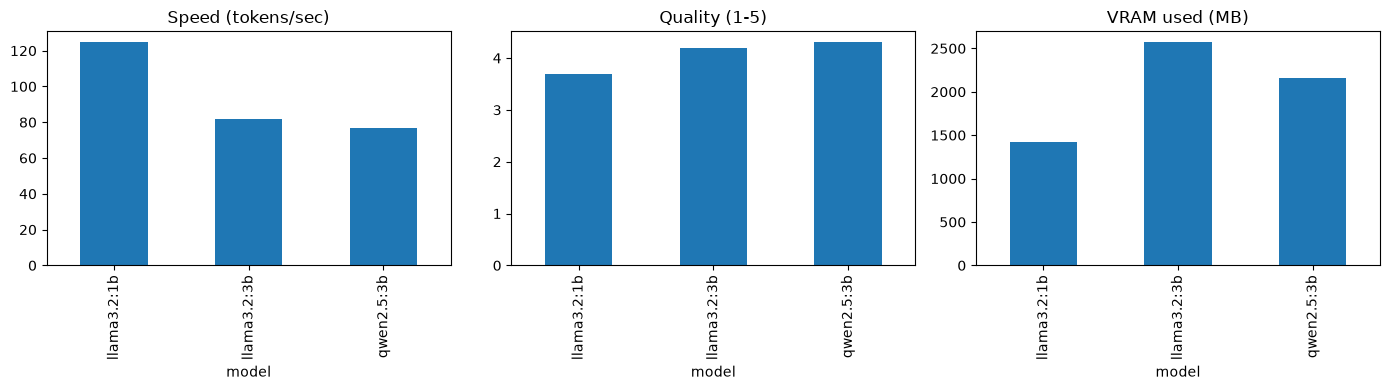

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14,4))
summary["avg_tokens_per_sec"].plot.bar(ax=ax[0], title="Speed (tokens/sec)")
summary["avg_quality_1to5"].plot.bar(ax=ax[1], title="Quality (1-5)")
summary["vram_mb"].plot.bar(ax=ax[2], title="VRAM used (MB)")
plt.tight_layout()
plt.savefig("../results/benchmark_phase1_chart.png", dpi=150)